# Global Disaster Records: Distribution, Loss & Coverage

## tl;dr
This portfolio edition re-examines a course dataset using one consistent 1970–2020 window.
The unit is a **country-level disaster impact record**, not necessarily a distinct global event.
Key findings and exact denominators are computed below; missing impacts remain unknown.

## Context & Methods
Questions: How are recorded impacts distributed? How concentrated are reported losses? How much data is missing?

### Key Assumptions
- Use the legacy `Year` field consistently; exclude 2021 because snapshot completeness is unverified.
- Count all unique country-impact records, including unnamed ones.
- Report nominal USD without causal or inflation-adjusted claims.
- Do not interpret globally aggregated months as Northern Hemisphere seasons.

See [data provenance](../docs/DATA.md) and [method revisions](../docs/METHODOLOGY.md).


In [1]:
from pathlib import Path
import os
import sys

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from IPython.display import display, Image, Markdown
from src.analysis import load_data, prepare, summarize, tables
from src.run import run

INPUT = Path("data/raw/1970-2021_DISASTERS.csv")


## Data
Raw data is not distributed. Follow `docs/DATA.md` to supply the compatible CSV. No raw row previews are saved in this notebook.

In [2]:
df, summary = run(INPUT)
t = tables(df)
p = summary["pareto"]
display(Markdown(
    f"**{summary['records']:,} country-impact records**, "
    f"{summary['distinct_event_ids']:,} distinct event IDs, "
    f"{summary['countries']} countries/territories. "
    f"Loss data missing: **{summary['damage_missing_pct']:.2f}%**. "
    f"Among {p['observed_records']:,} records with loss data, "
    f"the top **{p['top_records']:,} ({p['top_share_pct']:.2f}%)** "
    "account for 80% of reported loss."
))
display(t["quality"].round(2))


**14,329 country-impact records**, 12,660 distinct event IDs, 228 countries/territories. Loss data missing: **66.62%**. Among 4,783 records with loss data, the top **486 (10.16%)** account for 80% of reported loss.

,field,observed,missing,missing_pct
0,Total Deaths,10008,4321,30.16
1,Total Affected,10771,3558,24.83
2,Total Damages ('000 US$),4783,9546,66.62
3,Start Month,14063,266,1.86


## Results
### Recorded distribution
Counts reflect reporting coverage as well as hazard occurrence. Regional totals are not normalized risk rates.

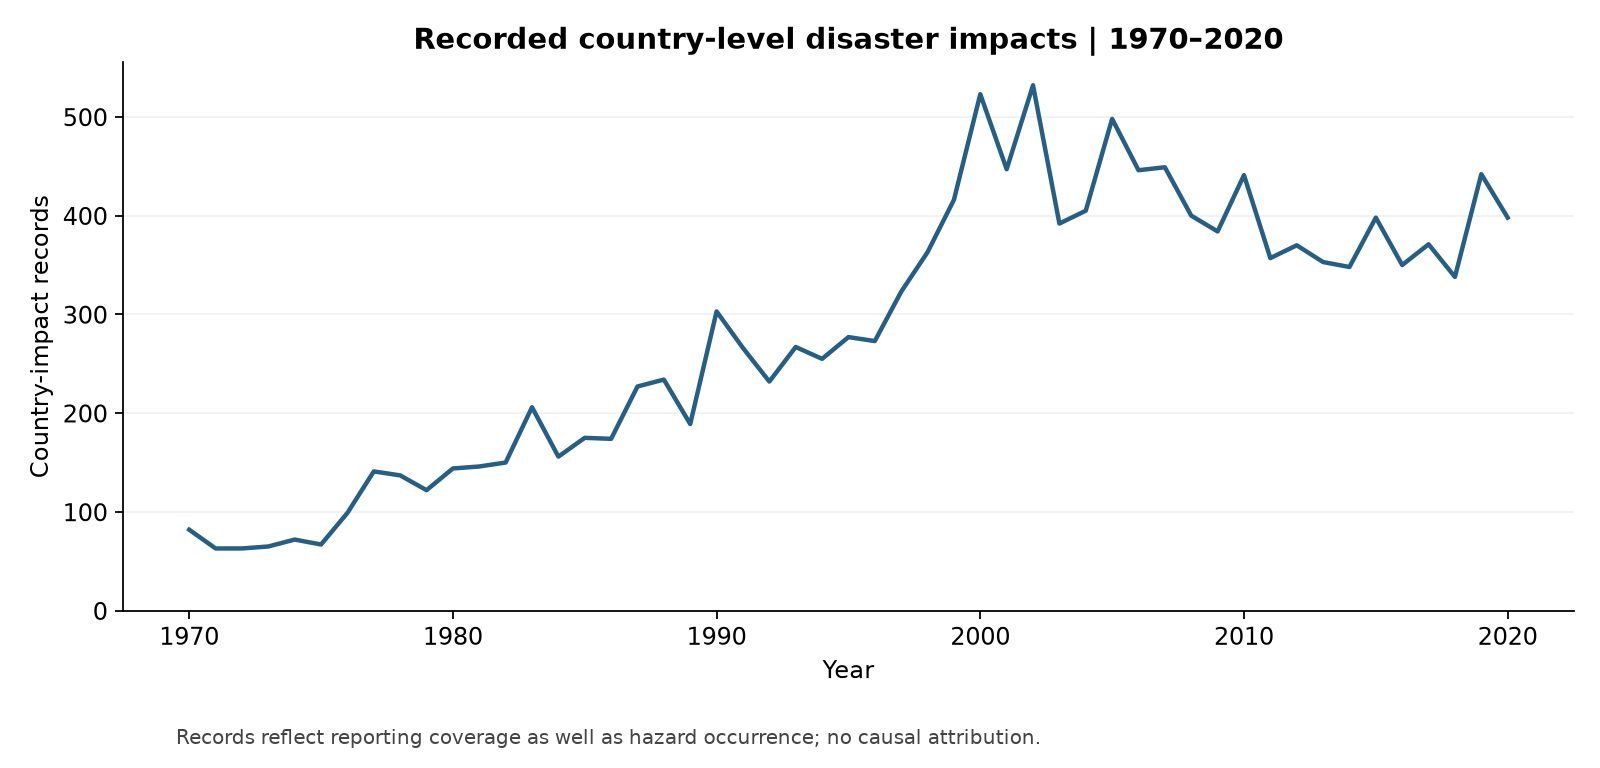

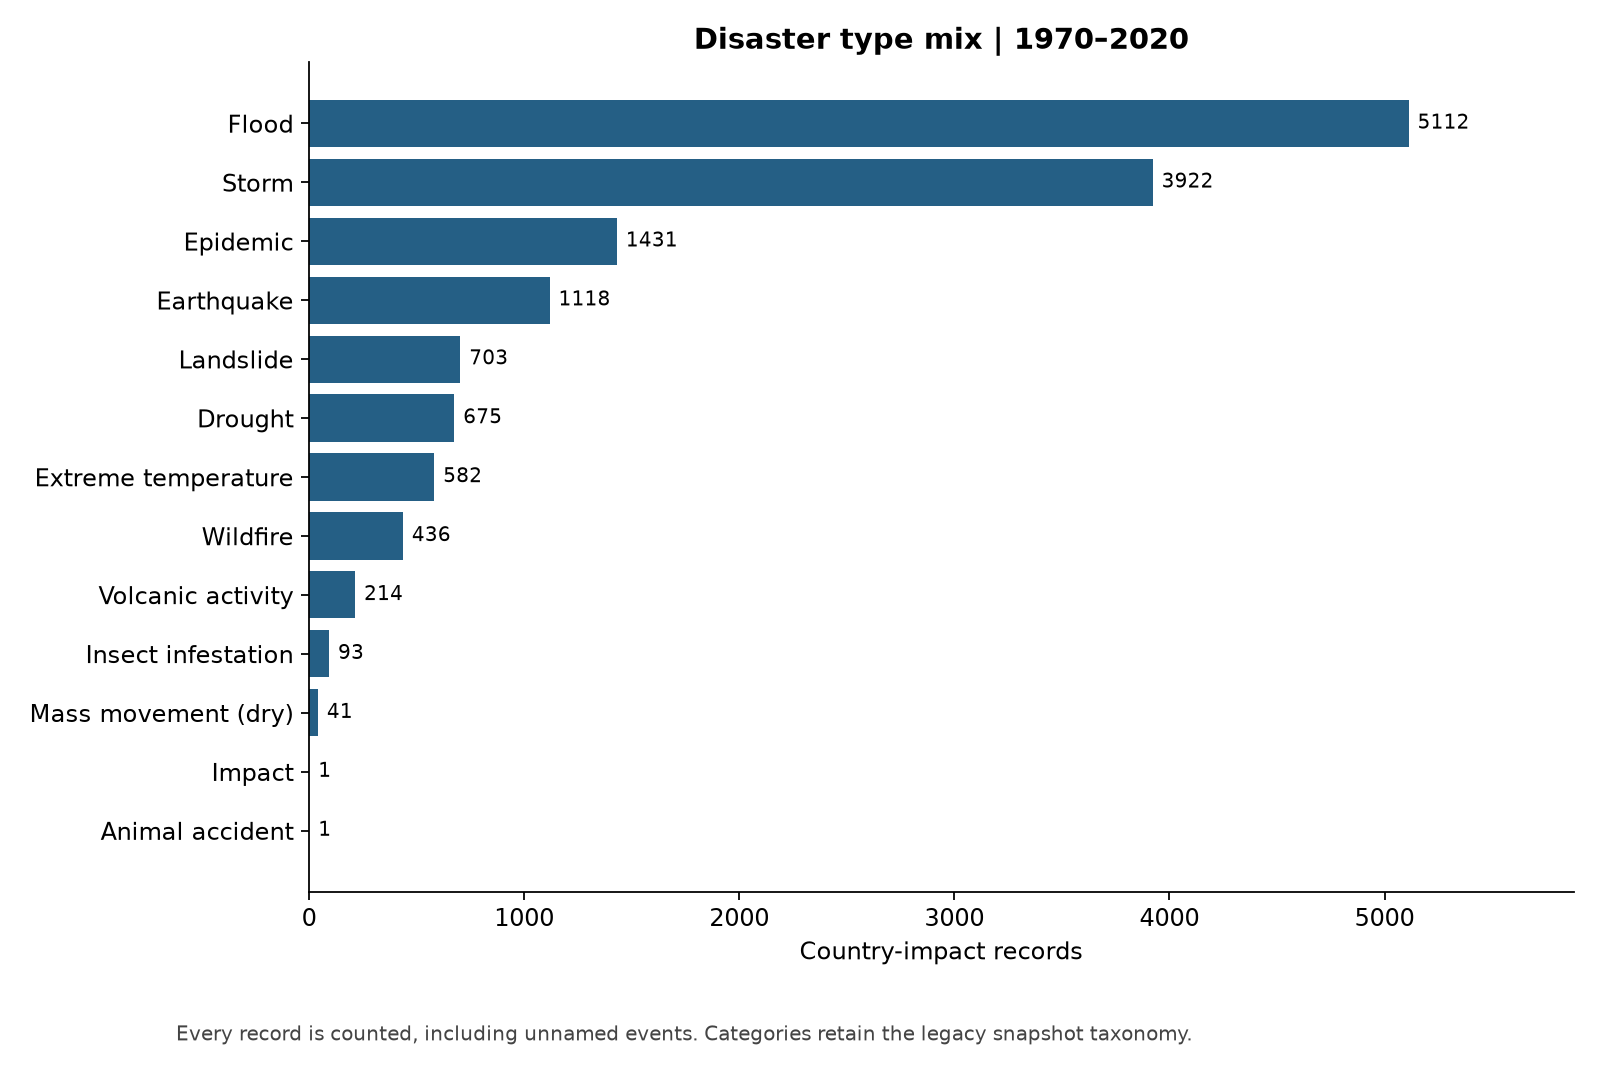

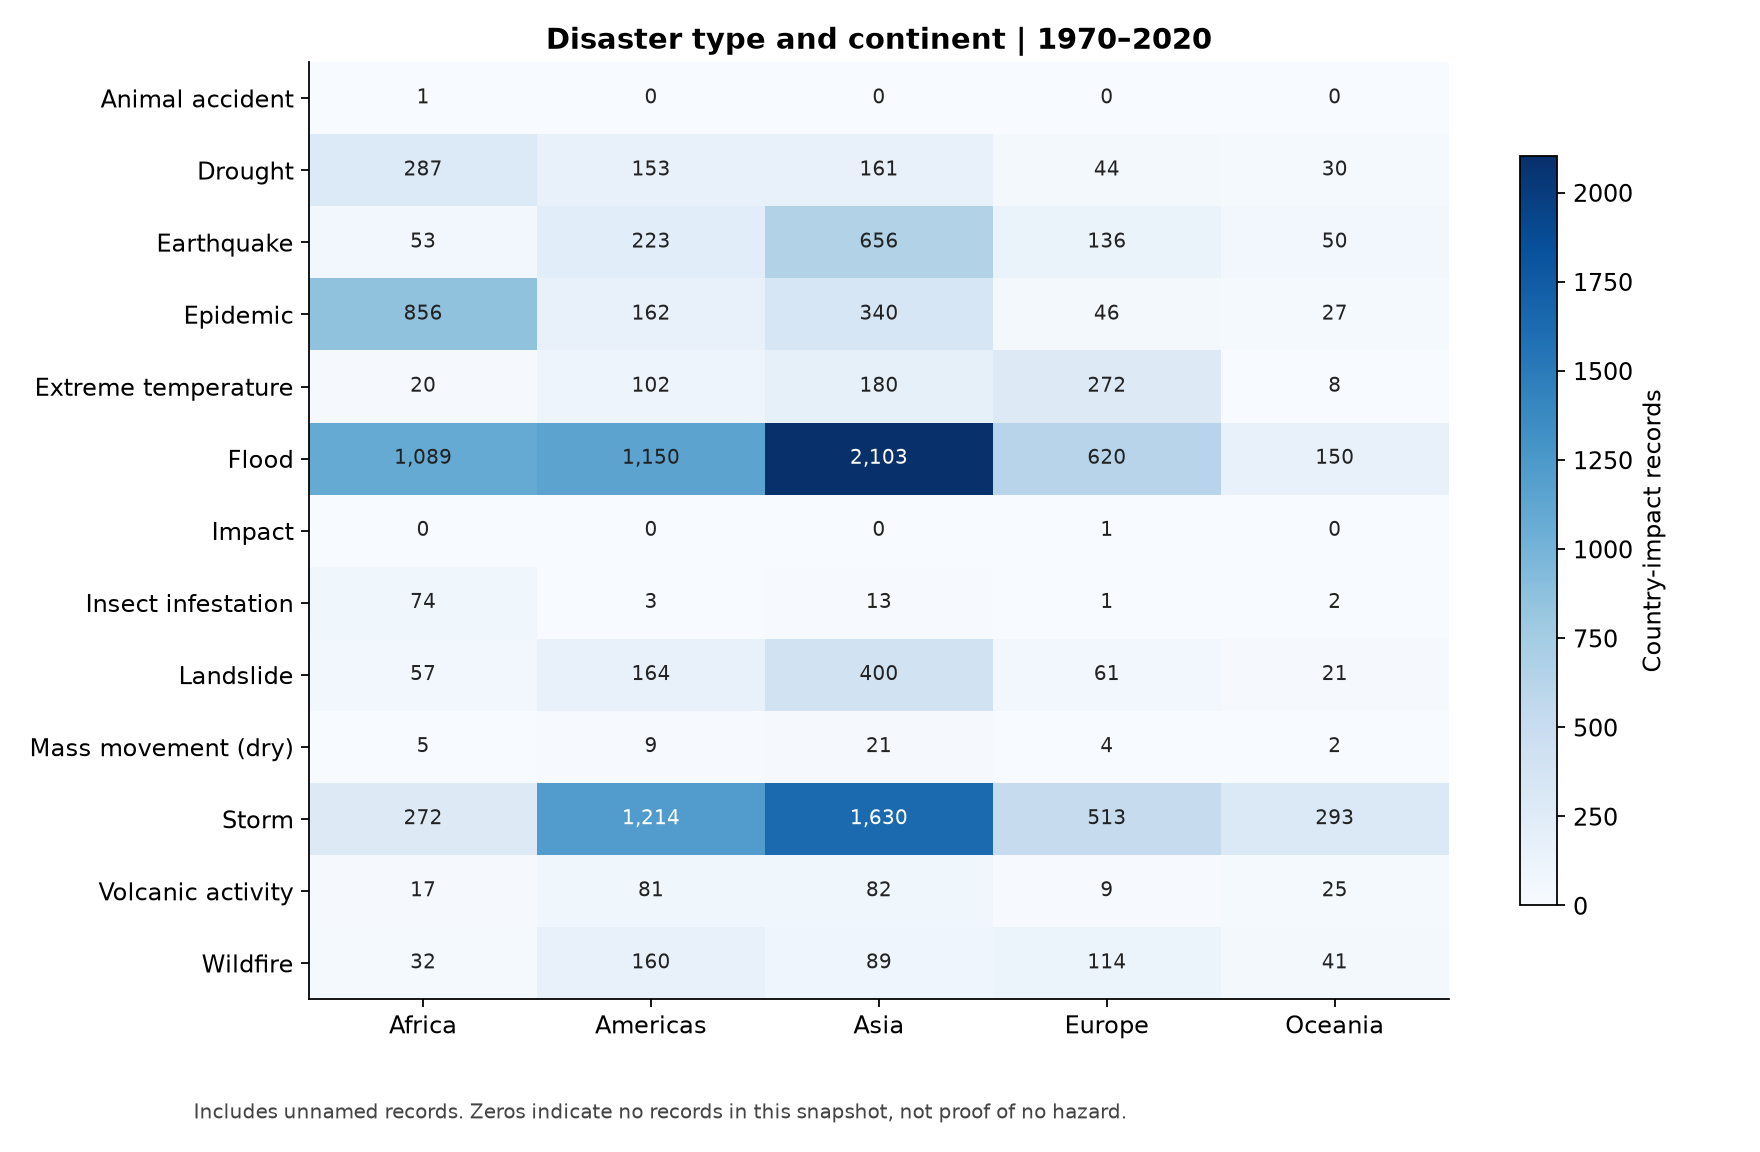

,Country,ISO,records,damage_observed,reported_damage_thousand_usd,deaths_observed,reported_deaths,damage_coverage_pct,deaths_coverage_pct
213,United States of America (the),USA,920,561,1.177164e+09,614,17556.0,60.98,66.74
40,China,CHN,895,537,5.832000e+08,711,457982.0,60.00,79.44
89,India,IND,645,179,1.372645e+08,590,204014.0,27.75,91.47
155,Philippines (the),PHL,602,355,2.845229e+07,489,61831.0,58.97,81.23
90,Indonesia,IDN,512,135,3.371101e+07,396,204283.0,26.37,77.34
15,Bangladesh,BGD,315,43,2.153609e+07,288,530673.0,13.65,91.43
98,Japan,JPN,266,122,5.195996e+08,215,32259.0,45.86,80.83
126,Mexico,MEX,253,89,5.387252e+07,203,17706.0,35.18,80.24
218,Viet Nam,VNM,237,132,2.332957e+07,214,18149.0,55.70,90.30
9,Australia,AUS,235,171,6.118810e+07,107,1389.0,72.77,45.53


In [3]:
display(Image(filename="reports/figures/01_annual_records.png"))
display(Image(filename="reports/figures/02_disaster_types.png"))
display(Image(filename="reports/figures/07_type_continent.png"))
display(t["countries"].sort_values("records", ascending=False).head(10).round(2))


### Missingness and economic loss
Concentration applies only to records with observed loss. Annual totals are reported nominal amounts, not inflation-adjusted or modeled global losses.

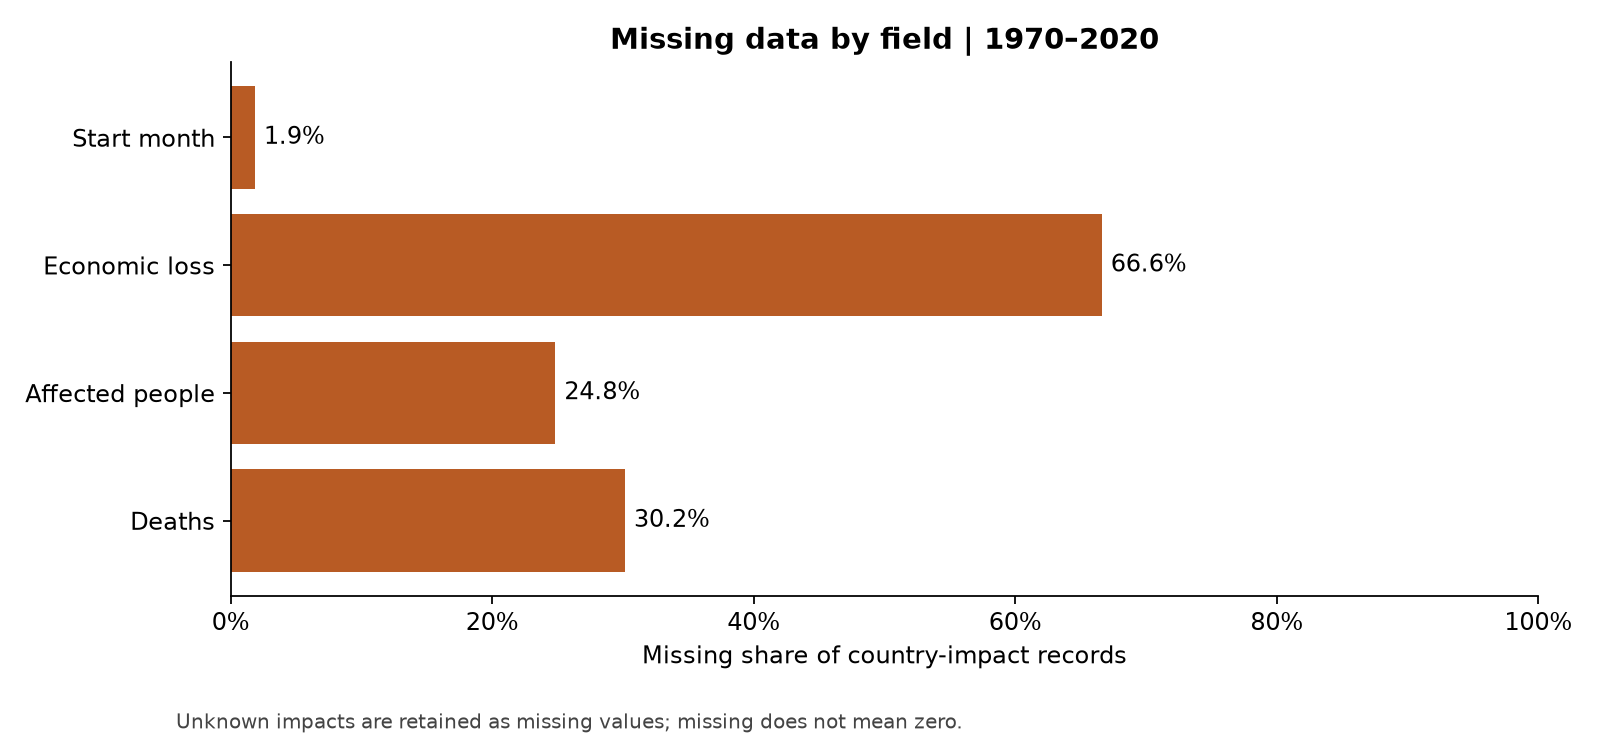

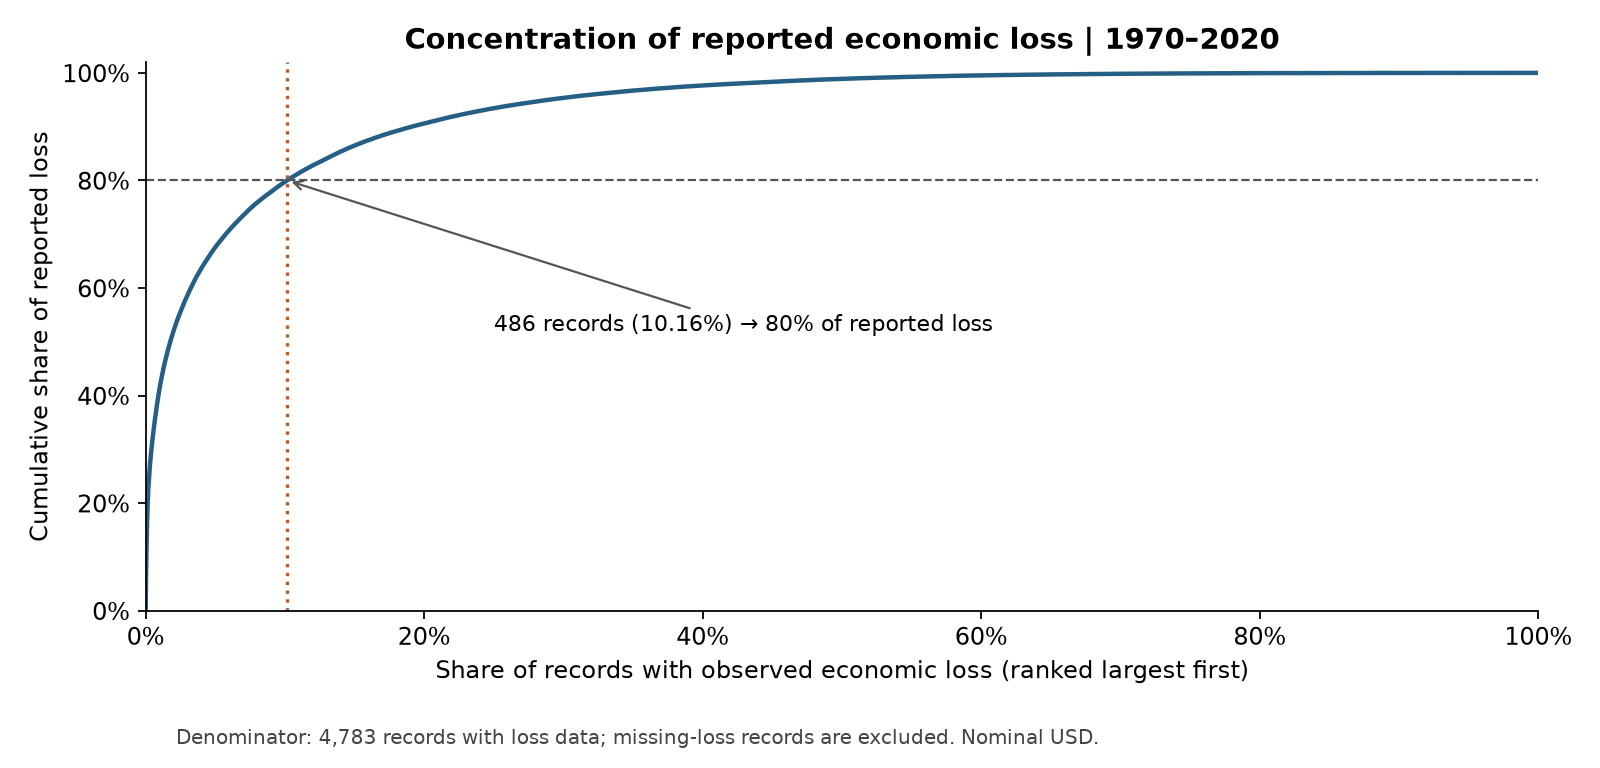

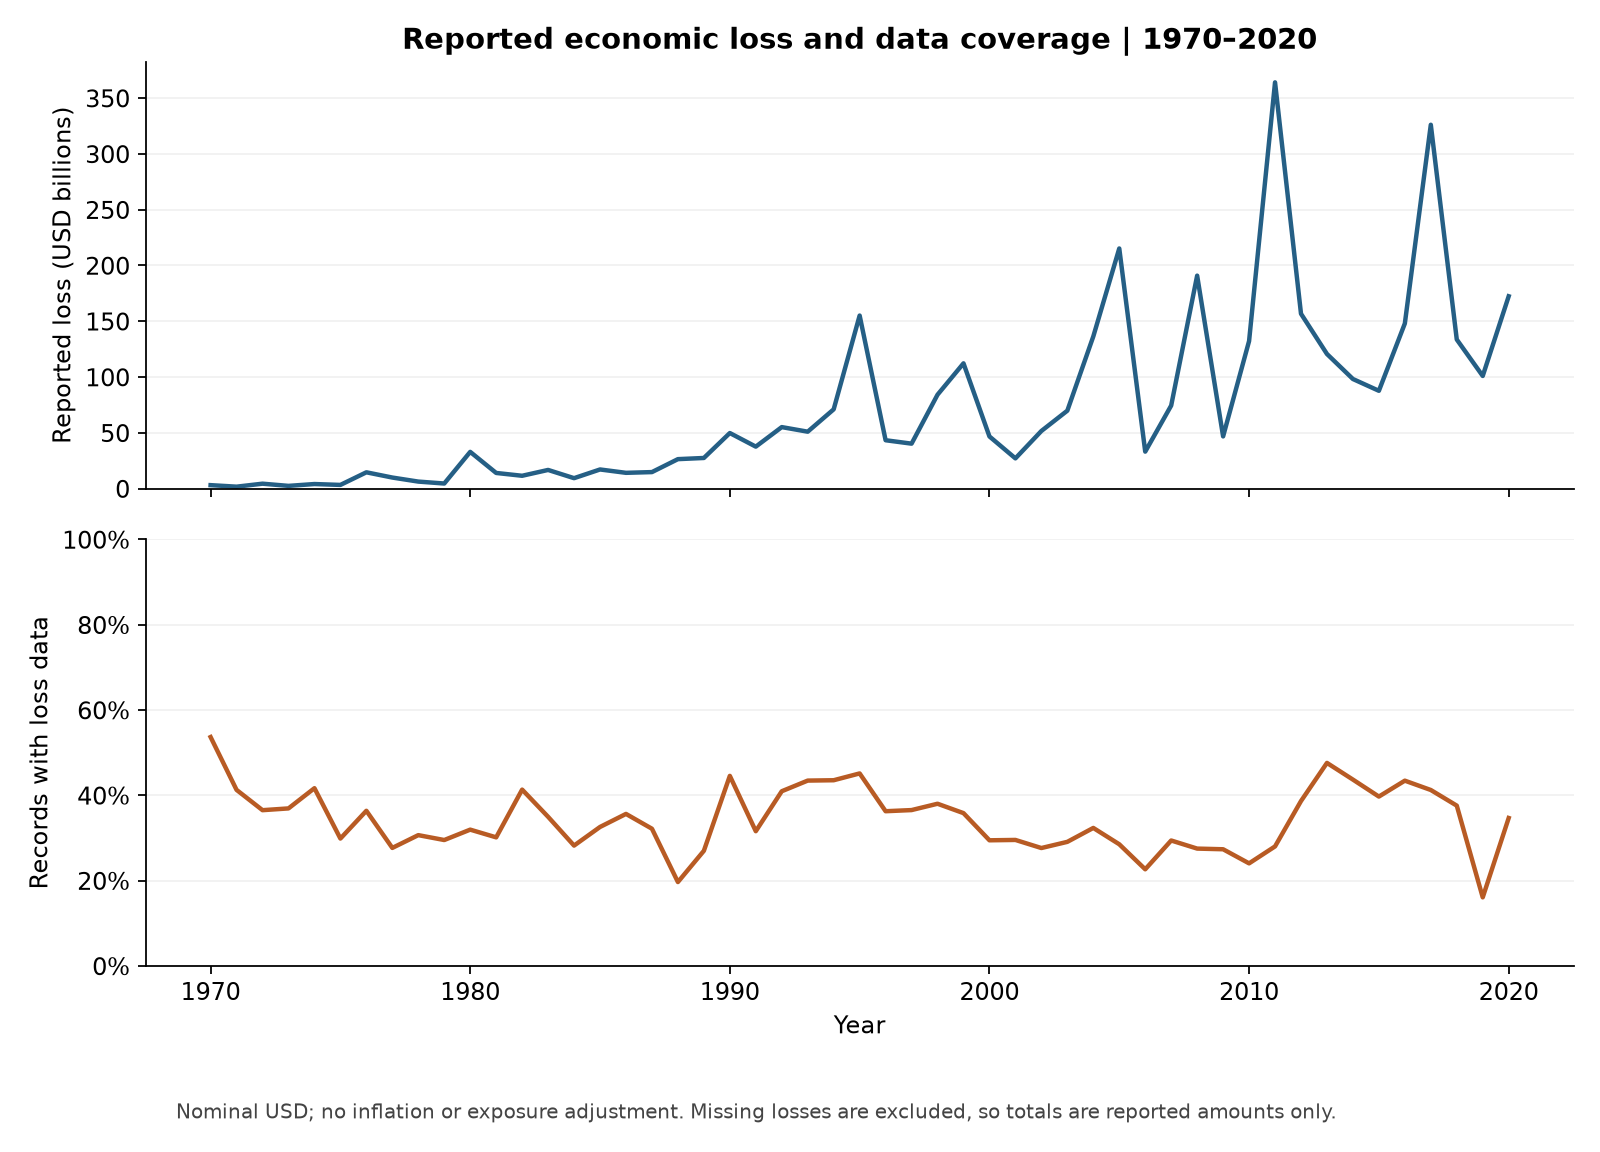

In [4]:
display(Image(filename="reports/figures/03_missingness.png"))
display(Image(filename="reports/figures/04_loss_concentration.png"))
display(Image(filename="reports/figures/05_loss_and_coverage.png"))


### Calendar month
Unknown months are excluded. The data does not support a globally uniform season label.

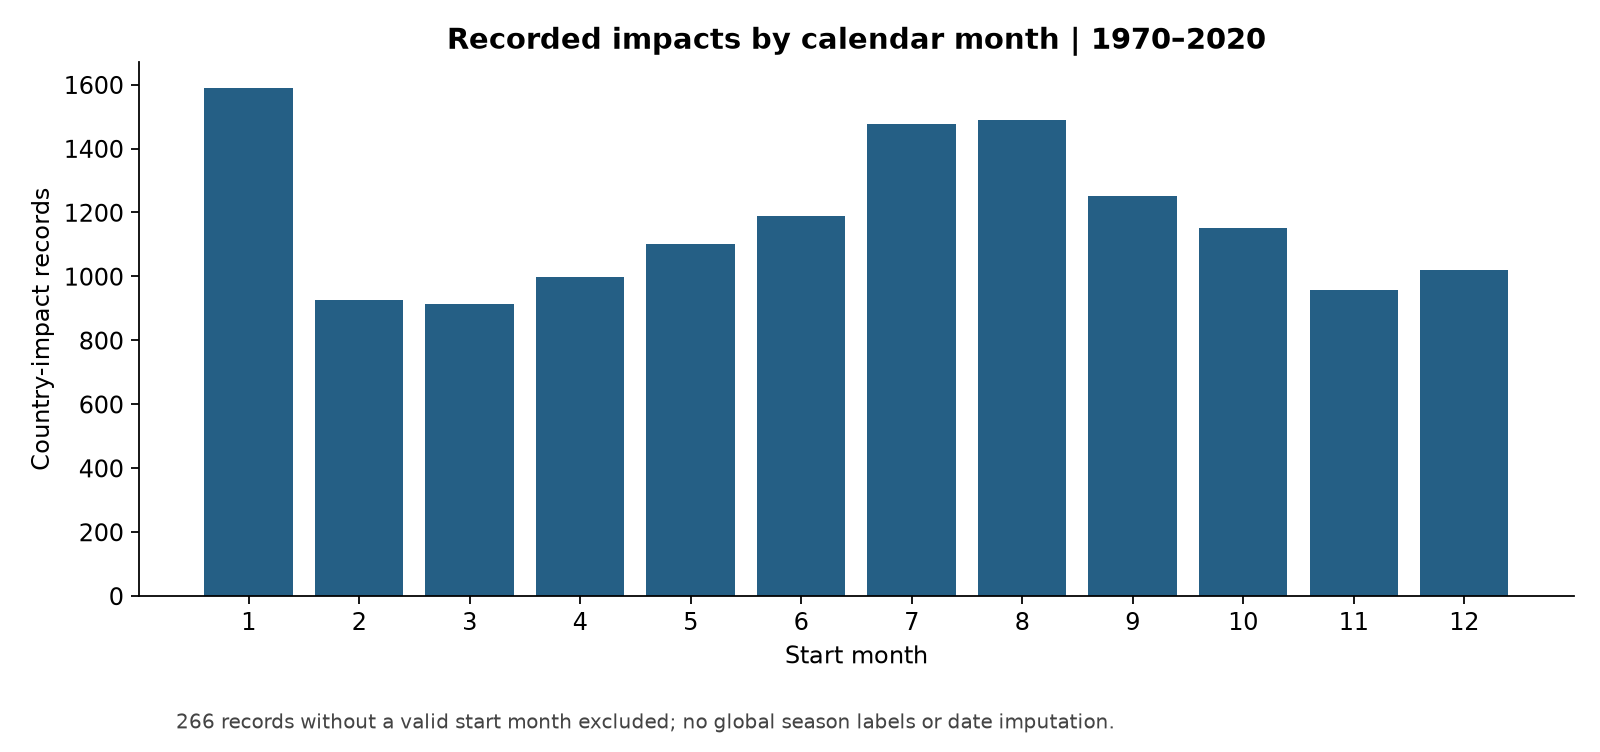

Aggregate counts reconcile with the selected population.


In [5]:
display(Image(filename="reports/figures/06_calendar_month.png"))
assert t["annual"]["records"].sum() == len(df)
assert t["types"]["records"].sum() == len(df)
assert t["type_continent"].to_numpy().sum() == len(df)
assert t["monthly"]["records"].sum() + df["Start Month"].isna().sum() == len(df)
print("Aggregate counts reconcile with the selected population.")


## Takeaways
- Evaluate record distribution and loss concentration alongside missing-data coverage.
- Prioritize investigation of high-loss records without generalizing observed-loss concentration to all disasters.
- Add inflation, exposure and comparable reporting controls before making cross-period risk claims.
- This is a descriptive historical case study; it does not estimate causal effects, predict disasters or price insurance.

The offline interactive country ranking is saved as `reports/figures/08_country_explorer.html`.
GitHub does not execute its JavaScript; download the file and open it locally.

Sources: [course dataset](https://www.kaggle.com/datasets/brsdincer/all-natural-disasters-19002021-eosdis),
[EM-DAT structure](https://doc.emdat.be/docs/data-structure-and-content/core-structure-of-the-database/),
[missing-data caveat](https://files.emdat.be/docs/20240725%20Caveat%20of%20missing%20data%20in%20EM-DAT.pdf).
